In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score

In [8]:
train = pd.read_csv(r'C:\Users\user\Downloads\train.csv')
test = pd.read_csv(r'C:\Users\user\Downloads\test.csv')

## 1- Explorer les données

In [10]:
train.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [11]:
train.shape

(891, 12)

In [12]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [13]:
 train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [16]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

<Axes: >

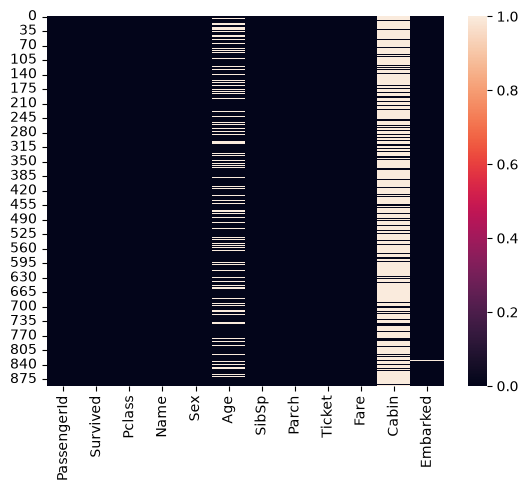

In [17]:
sns.heatmap(train.isnull())

In [18]:
train.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

## 2-Nettoyage des Donné

In [21]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [22]:
numerical_columns = train.select_dtypes(include=['int64', 'float64']).columns

## gestion des valeurs manquantes

In [23]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

train[numerical_columns] = imputer.fit_transform(train[numerical_columns])

In [24]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [26]:
categorical_columns = train.select_dtypes(
    include=['object', 'category', 'str']
).columns

In [27]:
from sklearn.impute import SimpleImputer

imputer_cat = SimpleImputer(strategy='most_frequent')

train[categorical_columns] = imputer_cat.fit_transform(train[categorical_columns])

In [28]:
train[categorical_columns].isnull().sum()

Name        0
Sex         0
Ticket      0
Cabin       0
Embarked    0
dtype: int64

In [29]:
missing_percent = train.isnull().mean() * 100

print(missing_percent)

PassengerId    0.0
Survived       0.0
Pclass         0.0
Name           0.0
Sex            0.0
Age            0.0
SibSp          0.0
Parch          0.0
Ticket         0.0
Fare           0.0
Cabin          0.0
Embarked       0.0
dtype: float64


In [30]:
train.isnull().sum().sum()

np.int64(0)

In [34]:
train = train.drop(columns=['Cabin'], errors='ignore')

In [35]:
print(train.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='str')


<Axes: >

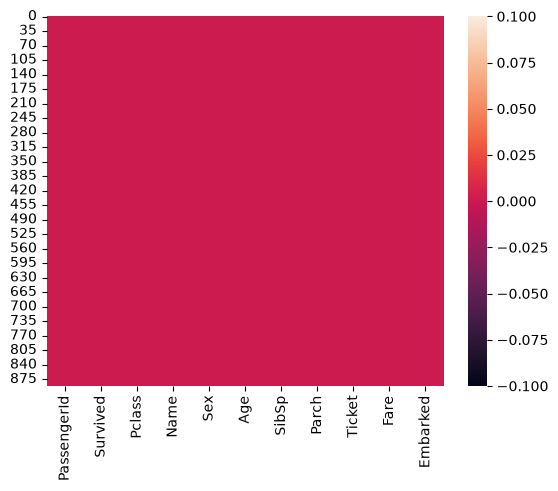

In [36]:
sns.heatmap(train.isnull())

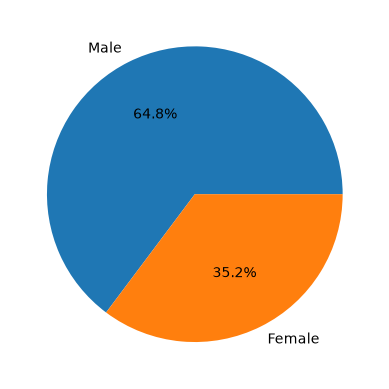

In [60]:
train['Sex_male'].value_counts().plot.pie(
    labels=['Male', 'Female'],
    autopct='%1.1f%%'
)
plt.show()

<Axes: xlabel='Age', ylabel='Count'>

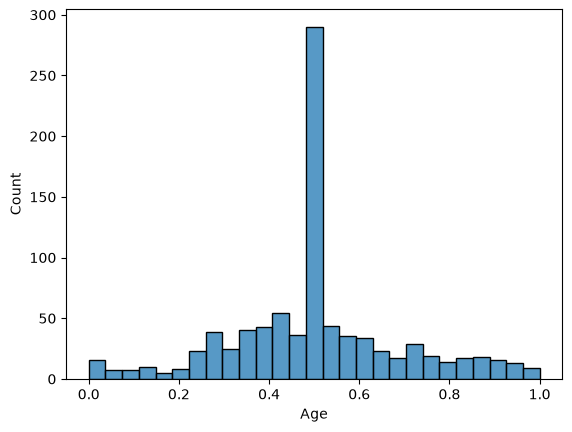

In [63]:
sns.histplot(train.Age)

## gestion des valeurs aberrantes

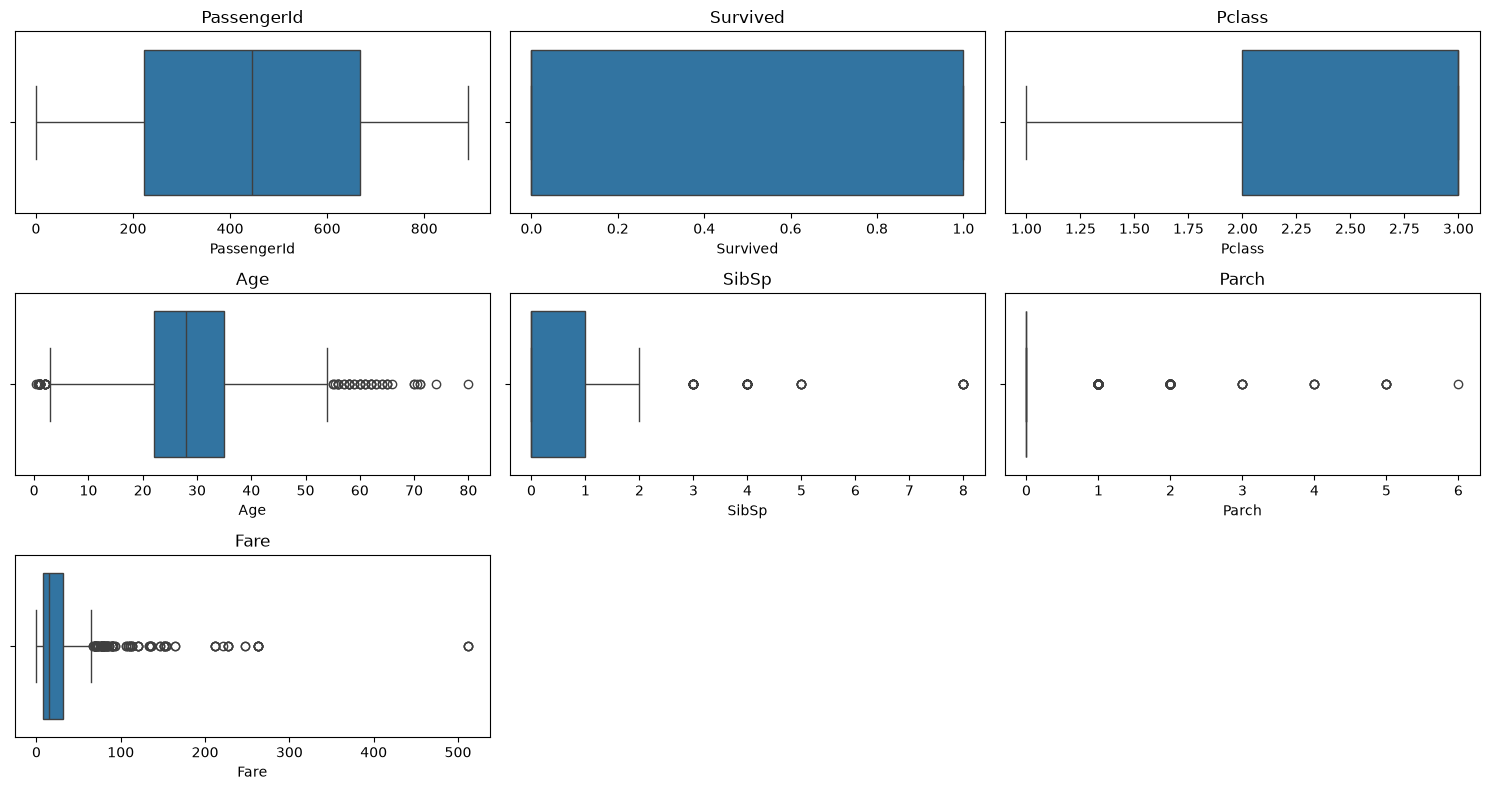

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = train.select_dtypes(include='number').columns

plt.figure(figsize=(15, 8))

for i, col in enumerate(numerical_columns, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=train[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [40]:
numerical_columns = train.select_dtypes(include='number').columns

for col in numerical_columns:
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    median = train[col].median()

    train.loc[(train[col] < lower) | (train[col] > upper), col] = median

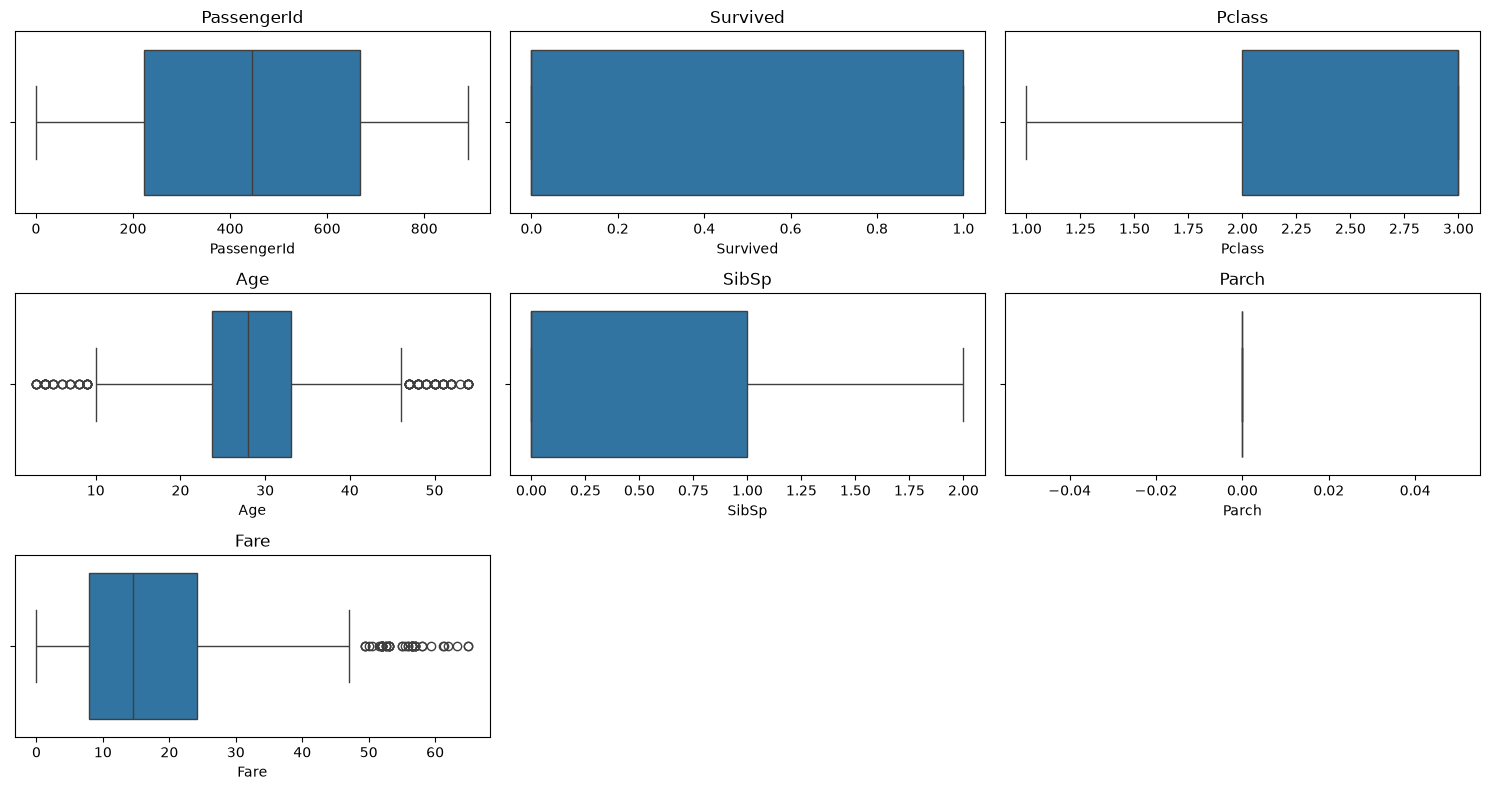

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 8))

for i, col in enumerate(numerical_columns, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=train[col])
    plt.title(col)

plt.tight_layout()
plt.show()

## 3- Transformation des Données

## encodage des variables catégorielles

In [43]:
categorical_columns = train.select_dtypes(include=['object', 'category', 'str']).columns

print("Colonnes catégorielles :")
print(categorical_columns)

Colonnes catégorielles :
Index(['Name', 'Sex', 'Ticket', 'Embarked'], dtype='str')


In [44]:
train = pd.get_dummies(
    train,
    columns=['Sex', 'Embarked'],
    drop_first=True,
    dtype=int
)

In [46]:
train.head(10)

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_male,Embarked_Q,Embarked_S
0,1.0,0.0,3.0,"Braund, Mr. Owen Harris",22.0,1.0,0.0,A/5 21171,7.2500,1,0,1
1,2.0,1.0,1.0,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1.0,0.0,PC 17599,14.4542,0,0,0
2,3.0,1.0,3.0,"Heikkinen, Miss. Laina",26.0,0.0,0.0,STON/O2. 3101282,7.9250,0,0,1
3,4.0,1.0,1.0,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1.0,0.0,113803,53.1000,0,0,1
4,5.0,0.0,3.0,"Allen, Mr. William Henry",35.0,0.0,0.0,373450,8.0500,1,0,1
5,6.0,0.0,3.0,"Moran, Mr. James",28.0,0.0,0.0,330877,8.4583,1,1,0
6,7.0,0.0,1.0,"McCarthy, Mr. Timothy J",54.0,0.0,0.0,17463,51.8625,1,0,1
7,8.0,0.0,3.0,"Palsson, Master. Gosta Leonard",28.0,0.0,0.0,349909,21.0750,1,0,1
8,9.0,1.0,3.0,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",27.0,0.0,0.0,347742,11.1333,0,0,1
9,10.0,1.0,2.0,"Nasser, Mrs. Nicholas (Adele Achem)",14.0,1.0,0.0,237736,30.0708,0,0,0


In [47]:
train.dtypes

PassengerId    float64
Survived       float64
Pclass         float64
Name               str
Age            float64
SibSp          float64
Parch          float64
Ticket             str
Fare           float64
Sex_male         int64
Embarked_Q       int64
Embarked_S       int64
dtype: object

In [48]:
train.select_dtypes(include=['object', 'category', 'str']).columns

Index(['Name', 'Ticket'], dtype='str')

In [49]:
train['Pclass'].value_counts()

Pclass
3.0    491
1.0    216
2.0    184
Name: count, dtype: int64

## Normalisation et Standardisation des données 

In [50]:
from sklearn.preprocessing import MinMaxScaler

In [51]:
numerical_columns = train.select_dtypes(include='number').columns.drop(
    ['Survived', 'PassengerId'], errors='ignore'
)

print(numerical_columns)

Index(['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q',
       'Embarked_S'],
      dtype='str')


In [52]:
scaler = MinMaxScaler()

train[numerical_columns] = scaler.fit_transform(
    train[numerical_columns]
)

In [53]:
train[numerical_columns].describe()

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
count,891.000000,891.000000,891.000000,891.0,891.000000,891.000000,891.000000,891.000000
mean,0.654321,0.499549,0.148709,0.0,0.267440,0.647587,0.086420,0.725028
std,0.418036,0.192031,0.260824,0.0,0.195585,0.477990,0.281141,0.446751
min,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
25%,0.500000,0.406863,0.000000,0.0,0.121698,0.000000,0.000000,0.000000
50%,1.000000,0.490196,0.000000,0.0,0.222372,1.000000,0.000000,1.000000
75%,1.000000,0.588235,0.500000,0.0,0.371538,1.000000,0.000000,1.000000
max,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000,1.000000


In [64]:
train_minmax = train[numerical_columns].copy()

train_original = pd.DataFrame(
    scaler.inverse_transform(train_minmax),
    columns=numerical_columns,
    index=train.index
)

In [65]:
from sklearn.preprocessing import StandardScaler

standard_scaler = StandardScaler()

train_standardized = train.copy()

train_standardized[numerical_columns] = standard_scaler.fit_transform(
    train_original[numerical_columns]
)

In [66]:
print("Moyennes :")
print(train_standardized[numerical_columns].mean())

print("\nEcart-types :")
print(train_standardized[numerical_columns].std())

Moyennes :
Pclass       -8.772133e-17
Age          -7.177199e-17
SibSp         8.572766e-17
Parch         0.000000e+00
Fare         -1.036707e-16
Sex_male     -1.156327e-16
Embarked_Q    0.000000e+00
Embarked_S   -8.373399e-17
dtype: float64

Ecart-types :
Pclass        1.000562
Age           1.000562
SibSp         1.000562
Parch         0.000000
Fare          1.000562
Sex_male      1.000562
Embarked_Q    1.000562
Embarked_S    1.000562
dtype: float64


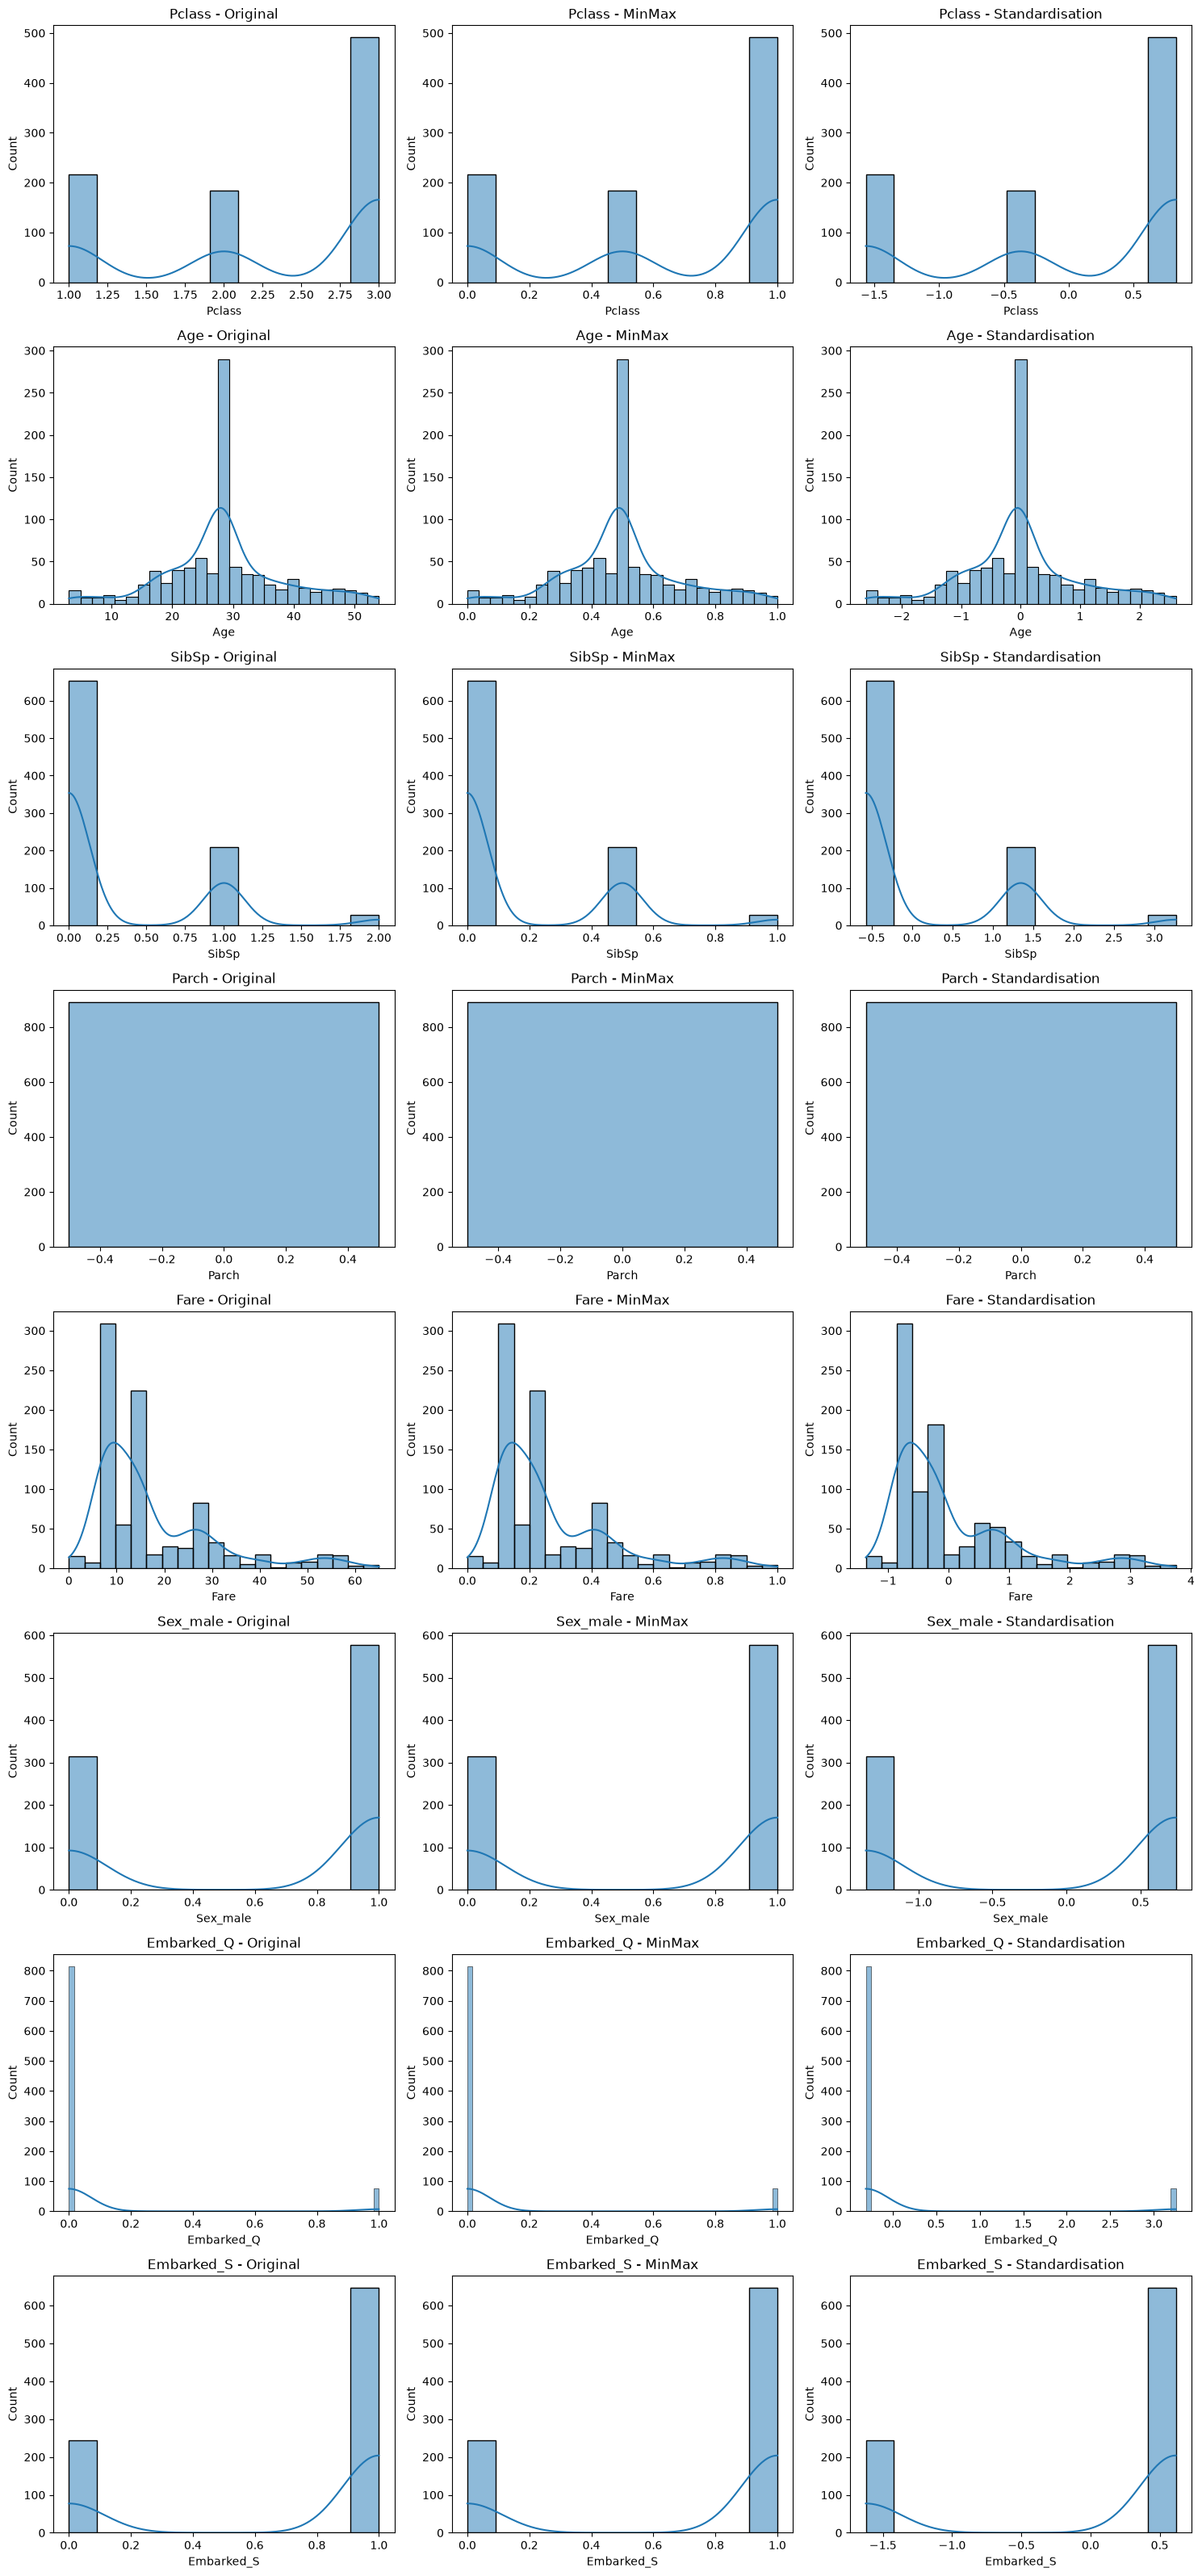

In [68]:
fig, axes = plt.subplots(
    len(numerical_columns), 3,
    figsize=(15, 4 * len(numerical_columns))
)

for i, col in enumerate(numerical_columns):

    sns.histplot(train_original[col], kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'{col} - Original')

    sns.histplot(train_minmax[col], kde=True, ax=axes[i, 1])
    axes[i, 1].set_title(f'{col} - MinMax')

    sns.histplot(train_standardized[col], kde=True, ax=axes[i, 2])
    axes[i, 2].set_title(f'{col} - Standardisation')

plt.tight_layout()
plt.show()

## 4-Gestion des Données Déséquilibrées


## Identification du déséquilibre des classes

In [69]:
train['Survived'].value_counts()

Survived
0.0    549
1.0    342
Name: count, dtype: int64

In [70]:
train['Survived'].value_counts(normalize=True) * 100

Survived
0.0    61.616162
1.0    38.383838
Name: proportion, dtype: float64

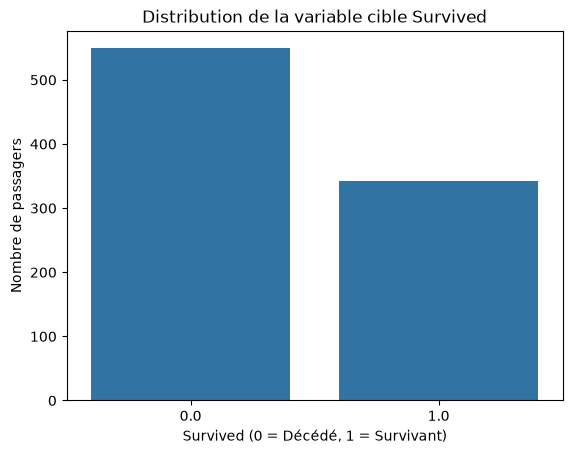

In [71]:
sns.countplot(x='Survived', data=train)
plt.title('Distribution de la variable cible Survived')
plt.xlabel('Survived (0 = Décédé, 1 = Survivant)')
plt.ylabel('Nombre de passagers')
plt.show()

## Gestion du déséquilibre

In [72]:
X = train.drop(columns=['Survived'])
y = train['Survived']

In [73]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)

X_under, y_under = rus.fit_resample(X, y)

In [74]:
print("Avant Undersampling :")
print(y.value_counts())

print("\nAprès Undersampling :")
print(y_under.value_counts())

Avant Undersampling :
Survived
0.0    549
1.0    342
Name: count, dtype: int64

Après Undersampling :
Survived
0.0    342
1.0    342
Name: count, dtype: int64


In [75]:
train_under = X_under.copy()
train_under['Survived'] = y_under

In [76]:
print(train_under.shape)
print(train_under['Survived'].value_counts())

(684, 12)
Survived
0.0    342
1.0    342
Name: count, dtype: int64


In [77]:
X_smote = train.drop(
    columns=['Survived', 'PassengerId', 'Name', 'Ticket'],
    errors='ignore'
)

y_smote = train['Survived']

In [78]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_smote_res, y_smote_res = smote.fit_resample(X_smote, y_smote)

In [80]:
train_smote = X_smote_res.copy()
train_smote['Survived'] = y_smote_res

In [81]:
print("Avant SMOTE :")
print(y_smote.value_counts())

print("\nAprès SMOTE :")
print(y_smote_res.value_counts())

print("Nouvelle taille :", train_smote.shape)

Avant SMOTE :
Survived
0.0    549
1.0    342
Name: count, dtype: int64

Après SMOTE :
Survived
0.0    549
1.0    549
Name: count, dtype: int64
Nouvelle taille : (1098, 9)


## TEST

In [82]:
print(imputer)
print(imputer_cat)
print(scaler)

SimpleImputer(strategy='median')
SimpleImputer(strategy='most_frequent')
MinMaxScaler()


In [83]:
print("Numerical Imputer:")
print(imputer.feature_names_in_)

print("\nCategorical Imputer:")
print(imputer_cat.feature_names_in_)

print("\nMinMax Scaler:")
print(scaler.feature_names_in_)

Numerical Imputer:
['PassengerId' 'Survived' 'Pclass' 'Age' 'SibSp' 'Parch' 'Fare']

Categorical Imputer:
['Name' 'Sex' 'Ticket' 'Cabin' 'Embarked']

MinMax Scaler:
['Pclass' 'Age' 'SibSp' 'Parch' 'Fare' 'Sex_male' 'Embarked_Q'
 'Embarked_S']


In [84]:

test = test.drop(columns=['Cabin'], errors='ignore')


num_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

for col in num_cols:
    idx = list(imputer.feature_names_in_).index(col)
    test[col] = test[col].fillna(imputer.statistics_[idx])


cat_cols = ['Name', 'Sex', 'Ticket', 'Embarked']

for col in cat_cols:
    idx = list(imputer_cat.feature_names_in_).index(col)
    test[col] = test[col].fillna(imputer_cat.statistics_[idx])

In [85]:
test = pd.get_dummies(
    test,
    columns=['Sex', 'Embarked'],
    drop_first=True,
    dtype=int
)

In [86]:
test = test.reindex(
    columns=[col for col in scaler.feature_names_in_ if col in test.columns]
    + [col for col in test.columns if col not in scaler.feature_names_in_],
    fill_value=0
)

In [87]:
test[scaler.feature_names_in_] = scaler.transform(
    test[scaler.feature_names_in_]
)

In [88]:
print(test.shape)
print(test.head())
print(test.isnull().sum())

(418, 11)
   Pclass       Age  SibSp  Parch      Fare  Sex_male  Embarked_Q  Embarked_S  \
0     1.0  0.617647    0.0    0.0  0.120449       1.0         1.0         0.0   
1     1.0  0.862745    0.5    0.0  0.107692       0.0         0.0         1.0   
2     0.5  1.156863    0.0    0.0  0.149038       1.0         1.0         0.0   
3     1.0  0.470588    0.0    0.0  0.133269       1.0         0.0         1.0   
4     1.0  0.372549    0.5    1.0  0.189038       0.0         0.0         1.0   

   PassengerId                                          Name   Ticket  
0          892                              Kelly, Mr. James   330911  
1          893              Wilkes, Mrs. James (Ellen Needs)   363272  
2          894                     Myles, Mr. Thomas Francis   240276  
3          895                              Wirz, Mr. Albert   315154  
4          896  Hirvonen, Mrs. Alexander (Helga E Lindqvist)  3101298  
Pclass         0
Age            0
SibSp          0
Parch          0
Far

In [89]:
print("Train columns:")
print(train.drop(columns=['Survived']).columns.tolist())

print("\nTest columns:")
print(test.columns.tolist())

Train columns:
['PassengerId', 'Pclass', 'Name', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']

Test columns:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'PassengerId', 'Name', 'Ticket']


In [90]:
X_train = train.drop(columns=['Survived'])

test = test.reindex(columns=X_train.columns)

print(X_train.columns.equals(test.columns))
print(X_train.shape)
print(test.shape)


True
(891, 11)
(418, 11)


In [91]:
X_train = X_train.drop(columns=['PassengerId', 'Name', 'Ticket'])
X_test = test.drop(columns=['PassengerId', 'Name', 'Ticket'])

y_train = train['Survived']

In [92]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)

(891, 8)
(418, 8)
(891,)


In [93]:
from sklearn.model_selection import train_test_split

X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [94]:
print(X_train_split.shape)
print(X_val.shape)
print(y_train_split.shape)
print(y_val.shape)

(712, 8)
(179, 8)
(712,)
(179,)


In [95]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000)

model_lr.fit(X_train_split, y_train_split)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [96]:
y_pred_lr = model_lr.predict(X_val)

In [97]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy :", accuracy_score(y_val, y_pred_lr))

print("\nConfusion Matrix :")
print(confusion_matrix(y_val, y_pred_lr))

print("\nClassification Report :")
print(classification_report(y_val, y_pred_lr))

Accuracy : 0.770949720670391

Confusion Matrix :
[[91 19]
 [22 47]]

Classification Report :
              precision    recall  f1-score   support

         0.0       0.81      0.83      0.82       110
         1.0       0.71      0.68      0.70        69

    accuracy                           0.77       179
   macro avg       0.76      0.75      0.76       179
weighted avg       0.77      0.77      0.77       179



In [98]:
from sklearn.neighbors import KNeighborsClassifier

model_knn = KNeighborsClassifier(n_neighbors=5)

model_knn.fit(X_train_split, y_train_split)

y_pred_knn = model_knn.predict(X_val)

In [99]:
print("Accuracy :", accuracy_score(y_val, y_pred_knn))
print(confusion_matrix(y_val, y_pred_knn))
print(classification_report(y_val, y_pred_knn))

Accuracy : 0.776536312849162
[[91 19]
 [21 48]]
              precision    recall  f1-score   support

         0.0       0.81      0.83      0.82       110
         1.0       0.72      0.70      0.71        69

    accuracy                           0.78       179
   macro avg       0.76      0.76      0.76       179
weighted avg       0.78      0.78      0.78       179



In [100]:
from sklearn.svm import SVC

model_svm = SVC(kernel='rbf')

model_svm.fit(X_train_split, y_train_split)

y_pred_svm = model_svm.predict(X_val)

In [101]:
print("Accuracy :", accuracy_score(y_val, y_pred_svm))
print(confusion_matrix(y_val, y_pred_svm))
print(classification_report(y_val, y_pred_svm))

Accuracy : 0.7932960893854749
[[104   6]
 [ 31  38]]
              precision    recall  f1-score   support

         0.0       0.77      0.95      0.85       110
         1.0       0.86      0.55      0.67        69

    accuracy                           0.79       179
   macro avg       0.82      0.75      0.76       179
weighted avg       0.81      0.79      0.78       179



In [102]:
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(random_state=42)

model_dt.fit(X_train_split, y_train_split)

y_pred_dt = model_dt.predict(X_val)

In [103]:
print("Accuracy :", accuracy_score(y_val, y_pred_dt))
print(confusion_matrix(y_val, y_pred_dt))
print(classification_report(y_val, y_pred_dt))

Accuracy : 0.776536312849162
[[91 19]
 [21 48]]
              precision    recall  f1-score   support

         0.0       0.81      0.83      0.82       110
         1.0       0.72      0.70      0.71        69

    accuracy                           0.78       179
   macro avg       0.76      0.76      0.76       179
weighted avg       0.78      0.78      0.78       179



In [104]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model_rf.fit(X_train_split, y_train_split)

y_pred_rf = model_rf.predict(X_val)

In [105]:
print("Accuracy :", accuracy_score(y_val, y_pred_rf))
print(confusion_matrix(y_val, y_pred_rf))
print(classification_report(y_val, y_pred_rf))

Accuracy : 0.7932960893854749
[[92 18]
 [19 50]]
              precision    recall  f1-score   support

         0.0       0.83      0.84      0.83       110
         1.0       0.74      0.72      0.73        69

    accuracy                           0.79       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.79      0.79       179



In [106]:
from sklearn.model_selection import GridSearchCV

param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_rf.fit(X_train_split, y_train_split)

print("Best Parameters:", grid_rf.best_params_)
print("Best CV Accuracy:", grid_rf.best_score_)

Best Parameters: {'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 300}
Best CV Accuracy: 0.8132768639810892


In [107]:
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

grid_svm = GridSearchCV(
    SVC(),
    param_grid_svm,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_svm.fit(X_train_split, y_train_split)

print("Best Parameters:", grid_svm.best_params_)
print("Best CV Accuracy:", grid_svm.best_score_)

Best Parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV Accuracy: 0.8160642174726682


In [108]:
best_rf = grid_rf.best_estimator_

y_pred_best_rf = best_rf.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_pred_best_rf))
print(confusion_matrix(y_val, y_pred_best_rf))
print(classification_report(y_val, y_pred_best_rf))

Accuracy: 0.7877094972067039
[[100  10]
 [ 28  41]]
              precision    recall  f1-score   support

         0.0       0.78      0.91      0.84       110
         1.0       0.80      0.59      0.68        69

    accuracy                           0.79       179
   macro avg       0.79      0.75      0.76       179
weighted avg       0.79      0.79      0.78       179



In [109]:
best_svm = grid_svm.best_estimator_

y_pred_best_svm = best_svm.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_pred_best_svm))
print(confusion_matrix(y_val, y_pred_best_svm))
print(classification_report(y_val, y_pred_best_svm))

Accuracy: 0.7932960893854749
[[104   6]
 [ 31  38]]
              precision    recall  f1-score   support

         0.0       0.77      0.95      0.85       110
         1.0       0.86      0.55      0.67        69

    accuracy                           0.79       179
   macro avg       0.82      0.75      0.76       179
weighted avg       0.81      0.79      0.78       179



In [110]:
best_rf = grid_rf.best_estimator_

y_pred_best_rf = best_rf.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_pred_best_rf))
print(confusion_matrix(y_val, y_pred_best_rf))
print(classification_report(y_val, y_pred_best_rf))


Accuracy: 0.7877094972067039
[[100  10]
 [ 28  41]]
              precision    recall  f1-score   support

         0.0       0.78      0.91      0.84       110
         1.0       0.80      0.59      0.68        69

    accuracy                           0.79       179
   macro avg       0.79      0.75      0.76       179
weighted avg       0.79      0.79      0.78       179



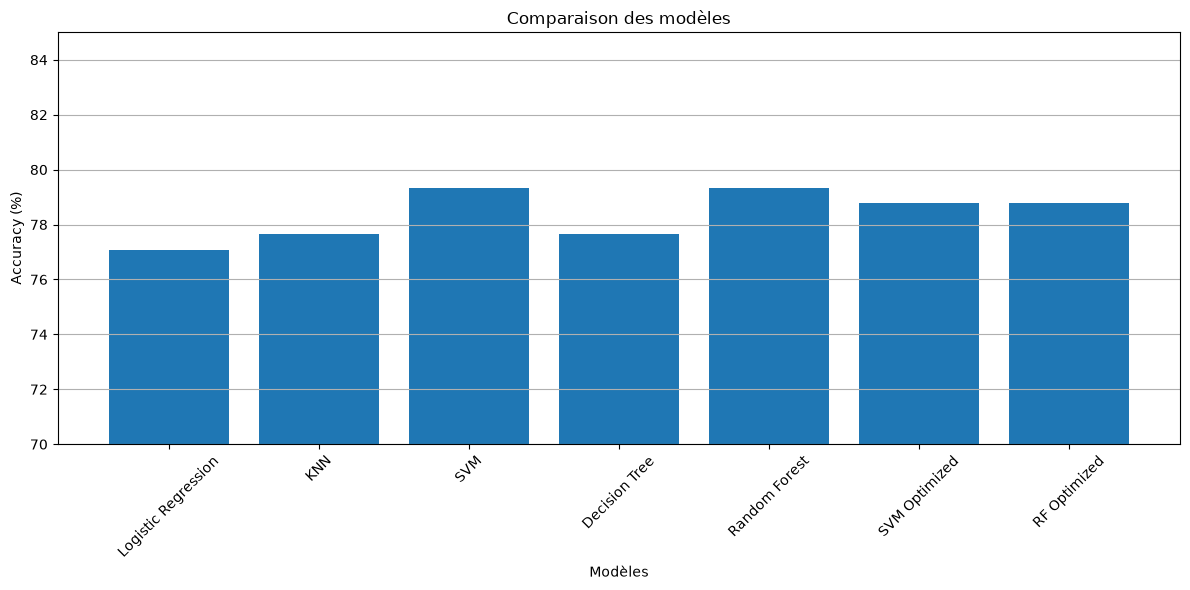

In [111]:
import matplotlib.pyplot as plt

models = [
    'Logistic Regression',
    'KNN',
    'SVM',
    'Decision Tree',
    'Random Forest',
    'SVM Optimized',
    'RF Optimized'
]

accuracies = [
    77.09, 77.65, 79.33, 77.65,
    79.33, 78.77, 78.77
]

plt.figure(figsize=(12, 6))
plt.bar(models, accuracies)

plt.title('Comparaison des modèles')
plt.xlabel('Modèles')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=45)
plt.ylim(70, 85)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [112]:
final_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

final_model.fit(X_train, y_train)

y_test_pred = final_model.predict(X_test)

In [113]:
print(y_test_pred[:20])
print(len(y_test_pred))

[0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 1. 1. 0. 1. 0. 0.]
418


In [114]:
submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived': y_test_pred.astype(int)
})

In [115]:
submission.to_csv('submission.csv', index=False)

In [116]:
print(submission.head())
print(submission.shape)

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         1
4          896         0
(418, 2)


In [117]:
import os
print(os.getcwd())

C:\Users\user
